# Entregable II — Sección 2: Reducción de dimensión

**Proyecto:** Estimación del riesgo de diabetes tipo 2 con datos del BRFSS 2025
**Curso:** Modelos y Simulación de Sistemas II — Universidad de Antioquia
**Autores:** Alejandro Gallego Alarcón, Andrés Eduardo Pabón Roldán, Paula Andrea Guarín Guarín

Este notebook reproduce la sección 2 del reporte. Parte de los mismos datos, la misma partición y la misma submuestra de búsqueda del notebook `01_entrenamiento_evaluacion.ipynb` (semilla 42), y trabaja con los dos modelos de mayor AUC de validación en esa sección: **regresión logística** (codificación A, C = 1) y **SVM con kernel RBF** (codificación C, C = 1, gamma = 0,01).

1. Análisis individual de variables: chi-cuadrado, V de Cramér, información mutua y AUC univariado, más la redundancia entre predictoras.
2. Eliminación de las variables candidatas y nueva evaluación de los dos modelos.
3. Extracción lineal con PCA.
4. Extracción no lineal con UMAP.
5. Comparación final en el conjunto de prueba.

Tiempo de ejecución aproximado: 1,5 a 2 horas con 2 núcleos (UMAP y la SVM son las etapas lentas).

In [1]:
try:
    import imblearn, umap  # noqa: F401
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn", "umap-learn"])

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (f1_score, make_scorer, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate,
                                     train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
import umap

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="umap")
warnings.filterwarnings("ignore", category=FutureWarning)

SEMILLA = 42
N_BUSQUEDA = 20_000
N_FINAL_SUB = 40_000     # submuestra para el ajuste final de la SVM y de UMAP
N_FOLDS = 5
N_JOBS = 2

os.makedirs("figuras", exist_ok=True)
os.makedirs("resultados", exist_ok=True)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6,
                     "legend.frameon": False, "legend.fontsize": 7.5, "lines.linewidth": 1.6,
                     "lines.markersize": 4.5})
COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]

## 0. Datos, partición y funciones comunes

Igual que en el notebook de la sección 1. Si `brfss2025_reducido.csv` no existe, se construye a partir del archivo del CDC.

In [3]:
URL_BRFSS = "https://www.cdc.gov/brfss/annual_data/2025/files/LLCP2025XPT.zip"
CSV_REDUCIDO = "brfss2025_reducido.csv"
OBJETIVO = "DIABETE4"
PREDICTORAS = ["_SEX", "_AGEG5YR", "_RACEGR3", "_EDUCAG", "_INCOMG1", "_BMI5CAT",
               "_TOTINDA", "_SMOKER3", "_RFDRHV9", "_FRTLT1A", "_VEGLT1A"]
NOMBRES = {"_SEX": "Sexo", "_AGEG5YR": "Edad", "_RACEGR3": "Raza/etnia",
           "_EDUCAG": "Educación", "_INCOMG1": "Ingreso", "_BMI5CAT": "IMC",
           "_TOTINDA": "Actividad física", "_SMOKER3": "Fumador",
           "_RFDRHV9": "Alcohol excesivo", "_FRTLT1A": "Frutas", "_VEGLT1A": "Vegetales"}

if not os.path.exists(CSV_REDUCIDO):
    import glob, urllib.request, zipfile
    if not glob.glob("LLCP2025*.XPT*"):
        if not os.path.exists("LLCP2025XPT.zip"):
            urllib.request.urlretrieve(URL_BRFSS, "LLCP2025XPT.zip")
        with zipfile.ZipFile("LLCP2025XPT.zip") as z:
            z.extractall(".")
    ruta_xpt = glob.glob("LLCP2025*.XPT*")[0]
    bloques = [b[[OBJETIVO] + PREDICTORAS]
               for b in pd.read_sas(ruta_xpt, format="xport", chunksize=50_000)]
    pd.concat(bloques, ignore_index=True).to_csv(CSV_REDUCIDO, index=False)

datos = pd.read_csv(CSV_REDUCIDO)
muestra = datos[datos[OBJETIVO].isin([1, 3])].reset_index(drop=True)
y = (muestra[OBJETIVO] == 1).astype(int)

CODIGO_FALTANTE = {c: 9 for c in PREDICTORAS}
CODIGO_FALTANTE["_AGEG5YR"] = 14
X = muestra[PREDICTORAS].copy()
for c in PREDICTORAS:
    X[c] = X[c].where(X[c] != CODIGO_FALTANTE[c])

X_ent, X_pru, y_ent, y_pru = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEMILLA)
X_bus, _, y_bus, _ = train_test_split(X_ent, y_ent, train_size=N_BUSQUEDA, stratify=y_ent, random_state=SEMILLA)
X_sub, _, y_sub, _ = train_test_split(X_ent, y_ent, train_size=N_FINAL_SUB, stratify=y_ent, random_state=SEMILLA)
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEMILLA)
print(f"Entrenamiento {len(y_ent):,} | prueba {len(y_pru):,} | búsqueda {len(y_bus):,} | submuestra final {len(y_sub):,}")

Entrenamiento 274,031 | prueba 68,508 | búsqueda 20,000 | submuestra final 40,000


In [4]:
METRICAS = {"auc": "roc_auc", "sens": "recall", "espec": make_scorer(recall_score, pos_label=0),
            "prec": make_scorer(precision_score, zero_division=0), "f1": "f1"}
ETIQUETA = {"auc": "AUC", "sens": "Sensibilidad", "espec": "Especificidad", "prec": "Precisión", "f1": "F1"}
ORDINALES = ["_AGEG5YR", "_EDUCAG", "_INCOMG1", "_BMI5CAT"]


def ic95(valores):
    v = np.asarray(valores, dtype=float)
    return stats.t.ppf(0.975, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v))


def fmt(v):
    return f"{np.mean(v):.2f} ± {ic95(v):.2f}"


def prep_A(variables):
    # Codificación A: faltante = categoría propia («no reportado») + one-hot
    return [("imputar", SimpleImputer(strategy="constant", fill_value=0)),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]


def prep_C(variables):
    # Codificación C: ordinales estandarizadas, nominales en one-hot, moda e indicador de faltante
    ordv = [c for c in variables if c in ORDINALES]
    nomv = [c for c in variables if c not in ORDINALES]
    partes = []
    if ordv:
        partes.append(("ord", Pipeline([("imputar", SimpleImputer(strategy="most_frequent", add_indicator=True)),
                                        ("escalar", StandardScaler())]), ordv))
    if nomv:
        partes.append(("nom", Pipeline([("imputar", SimpleImputer(strategy="most_frequent", add_indicator=True)),
                                        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), nomv))
    return [("prep", ColumnTransformer(partes))]


# Los dos mejores modelos de la sección 1, con sus hiperparámetros y su codificación
MEJORES = {
    "Regresión logística": {"prep": prep_A, "modelo": lambda: LogisticRegression(C=1, class_weight="balanced", max_iter=2000)},
    "SVM (RBF)": {"prep": prep_C, "modelo": lambda: SVC(kernel="rbf", C=1, gamma=0.01, class_weight="balanced")},
}


def pipeline(nombre, variables=PREDICTORAS, reductor=None, escalar_despues=False, modelo=None):
    pasos = MEJORES[nombre]["prep"](variables)
    if reductor is not None:
        pasos.append(("reductor", reductor))
    if escalar_despues:
        pasos.append(("escalar2", StandardScaler()))
    pasos.append(("modelo", modelo if modelo is not None else MEJORES[nombre]["modelo"]()))
    return Pipeline(pasos)


def evaluar_cv(pipe, variables=PREDICTORAS):
    r = cross_validate(pipe, X_bus[variables], y_bus, cv=cv, scoring=METRICAS, return_train_score=True, n_jobs=N_JOBS)
    return {f"{p}_{m}": r[f"{k}_{m}"] for p, k in [("ent", "train"), ("val", "test")] for m in METRICAS}


def dimension(nombre, variables=PREDICTORAS):
    return Pipeline(MEJORES[nombre]["prep"](variables)).fit(X_bus[variables]).transform(X_bus[variables].head(5)).shape[1]


for n in MEJORES:
    print(f"{n}: {dimension(n)} columnas después de la codificación")

Regresión logística: 57 columnas después de la codificación
SVM (RBF): 39 columnas después de la codificación


Resultado de referencia (todas las variables, sin reducción) con los mismos pliegues. Es la línea base contra la que se comparan la selección de variables, PCA y UMAP.

In [5]:
base_cv = {}
for n in MEJORES:
    t0 = time.time()
    base_cv[n] = evaluar_cv(pipeline(n))
    print(f"{n:20s} AUC val = {fmt(base_cv[n]['val_auc'])}  sens val = {fmt(base_cv[n]['val_sens'])}  ({time.time()-t0:.0f} s)")

Regresión logística  AUC val = 0.76 ± 0.01  sens val = 0.75 ± 0.01  (2 s)


SVM (RBF)            AUC val = 0.76 ± 0.01  sens val = 0.78 ± 0.01  (117 s)


## 1. Análisis individual de variables

Todo se calcula **solo con el conjunto de entrenamiento** (274.031 registros). Los faltantes se tratan como una categoría más («no reportado»), porque en la sección 1 se vio que en varias variables no responder se asocia con la diabetes.

- **Chi-cuadrado y V de Cramér:** asociación entre cada predictora y la diabetes. V va de 0 (independencia) a 1. Con 274 mil registros casi cualquier diferencia es significativa, así que la decisión se basa en la magnitud (V), no en el valor *p*.
- **Información mutua (bits):** cuánta incertidumbre sobre la diabetes elimina conocer la variable.
- **AUC univariado:** índice de discriminación de cada variable por separado. Cada categoría se reemplaza por la prevalencia de diabetes observada en ella (estimada fuera de pliegue, con 5 pliegues, para no ser optimista) y se calcula el AUC de ese puntaje.

In [6]:
def cramer_v(a, b):
    tabla = pd.crosstab(a, b)
    chi2, p, gl, _ = stats.chi2_contingency(tabla, correction=False)
    n = tabla.to_numpy().sum()
    k = min(tabla.shape) - 1
    return np.sqrt(chi2 / (n * k)), chi2, p, gl


Xc = X_ent.fillna(0).astype(int)      # 0 = «no reportado»
cv_ent = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
mi = mutual_info_classif(Xc, y_ent, discrete_features=True, random_state=SEMILLA) / np.log(2)
filas = []
for j, c in enumerate(PREDICTORAS):
    v, chi2, p, gl = cramer_v(Xc[c], y_ent)
    # puntaje fuera de pliegue: prevalencia de la categoría calculada en los otros 4 pliegues
    puntaje = np.zeros(len(y_ent))
    for i_a, i_b in cv_ent.split(Xc, y_ent):
        prev = y_ent.iloc[i_a].groupby(Xc[c].iloc[i_a].to_numpy()).mean()
        puntaje[i_b] = Xc[c].iloc[i_b].map(prev).fillna(y_ent.iloc[i_a].mean()).to_numpy()
    filas.append({"Variable": NOMBRES[c], "Categorías": Xc[c].nunique(), "chi2": round(chi2, 1), "gl": gl,
                  "valor p": p, "V de Cramér": v, "Información mutua (bits)": mi[j],
                  "AUC univariado": roc_auc_score(y_ent, puntaje)})
tabla_ind = pd.DataFrame(filas).sort_values("V de Cramér", ascending=False).reset_index(drop=True)
tabla_ind.to_csv("resultados/analisis_individual.csv", index=False)
tabla_ind.round({"V de Cramér": 2, "Información mutua (bits)": 4, "AUC univariado": 2})

,Variable,Categorías,chi2,gl,valor p,V de Cramér,Información mutua (bits),AUC univariado
0,Edad,14,14638.4,13,0.000000e+00,0.23,0.0471,0.68
1,IMC,5,7990.3,4,0.000000e+00,0.17,0.0210,0.63
2,Actividad física,3,5881.0,2,0.000000e+00,0.15,0.0141,0.59
3,Ingreso,8,4465.5,7,0.000000e+00,0.13,0.0119,0.60
4,Educación,5,2153.7,4,0.000000e+00,0.09,0.0056,0.56
5,Fumador,5,1114.3,4,6.019682e-240,0.06,0.0029,0.54
6,Alcohol excesivo,3,786.0,2,2.081577e-171,0.05,0.0024,0.52
7,Raza/etnia,6,707.9,5,9.419580e-151,0.05,0.0017,0.52
8,Vegetales,3,478.1,2,1.506517e-104,0.04,0.0012,0.52
9,Frutas,3,200.2,2,3.382233e-44,0.03,0.0005,0.52


### Redundancia entre predictoras

Una variable también puede sobrar si repite la información de otra. Se calcula la V de Cramér entre cada par de predictoras.

In [7]:
# Se calcula de dos formas: incluyendo «no reportado» como categoría y solo con los casos completos del par.
# La diferencia muestra cuánto de la asociación se debe a que las mismas personas dejan varias preguntas sin responder.
R = pd.DataFrame(np.eye(len(PREDICTORAS)), index=PREDICTORAS, columns=PREDICTORAS)
R_cc = R.copy()
for i, a in enumerate(PREDICTORAS):
    for b in PREDICTORAS[i + 1:]:
        R.loc[a, b] = R.loc[b, a] = cramer_v(Xc[a], Xc[b])[0]
        completos = (Xc[a] > 0) & (Xc[b] > 0)
        R_cc.loc[a, b] = R_cc.loc[b, a] = cramer_v(Xc.loc[completos, a], Xc.loc[completos, b])[0]
for M in (R, R_cc):
    M.index = M.columns = [NOMBRES[c] for c in PREDICTORAS]
R.to_csv("resultados/cramer_entre_predictoras.csv")
R_cc.to_csv("resultados/cramer_entre_predictoras_casos_completos.csv")
triu = np.triu(np.ones(R.shape, dtype=bool), 1)
pares = R.where(triu).stack().sort_values(ascending=False)
pares_cc = R_cc.where(triu).stack()
print("Pares más asociados (con «no reportado» | solo casos completos):")
print(pd.DataFrame({"con no reportado": pares, "casos completos": pares_cc[pares.index]}).head(8).round(2).to_string())

Pares más asociados (con «no reportado» | solo casos completos):
                                   con no reportado  casos completos
Frutas           Vegetales                     0.58             0.24
Fumador          Alcohol excesivo              0.54             0.13
Alcohol excesivo Frutas                        0.47             0.04
                 Vegetales                     0.43             0.02
Fumador          Frutas                        0.42             0.10
                 Vegetales                     0.38             0.04
IMC              Alcohol excesivo              0.28             0.02
                 Frutas                        0.24             0.09


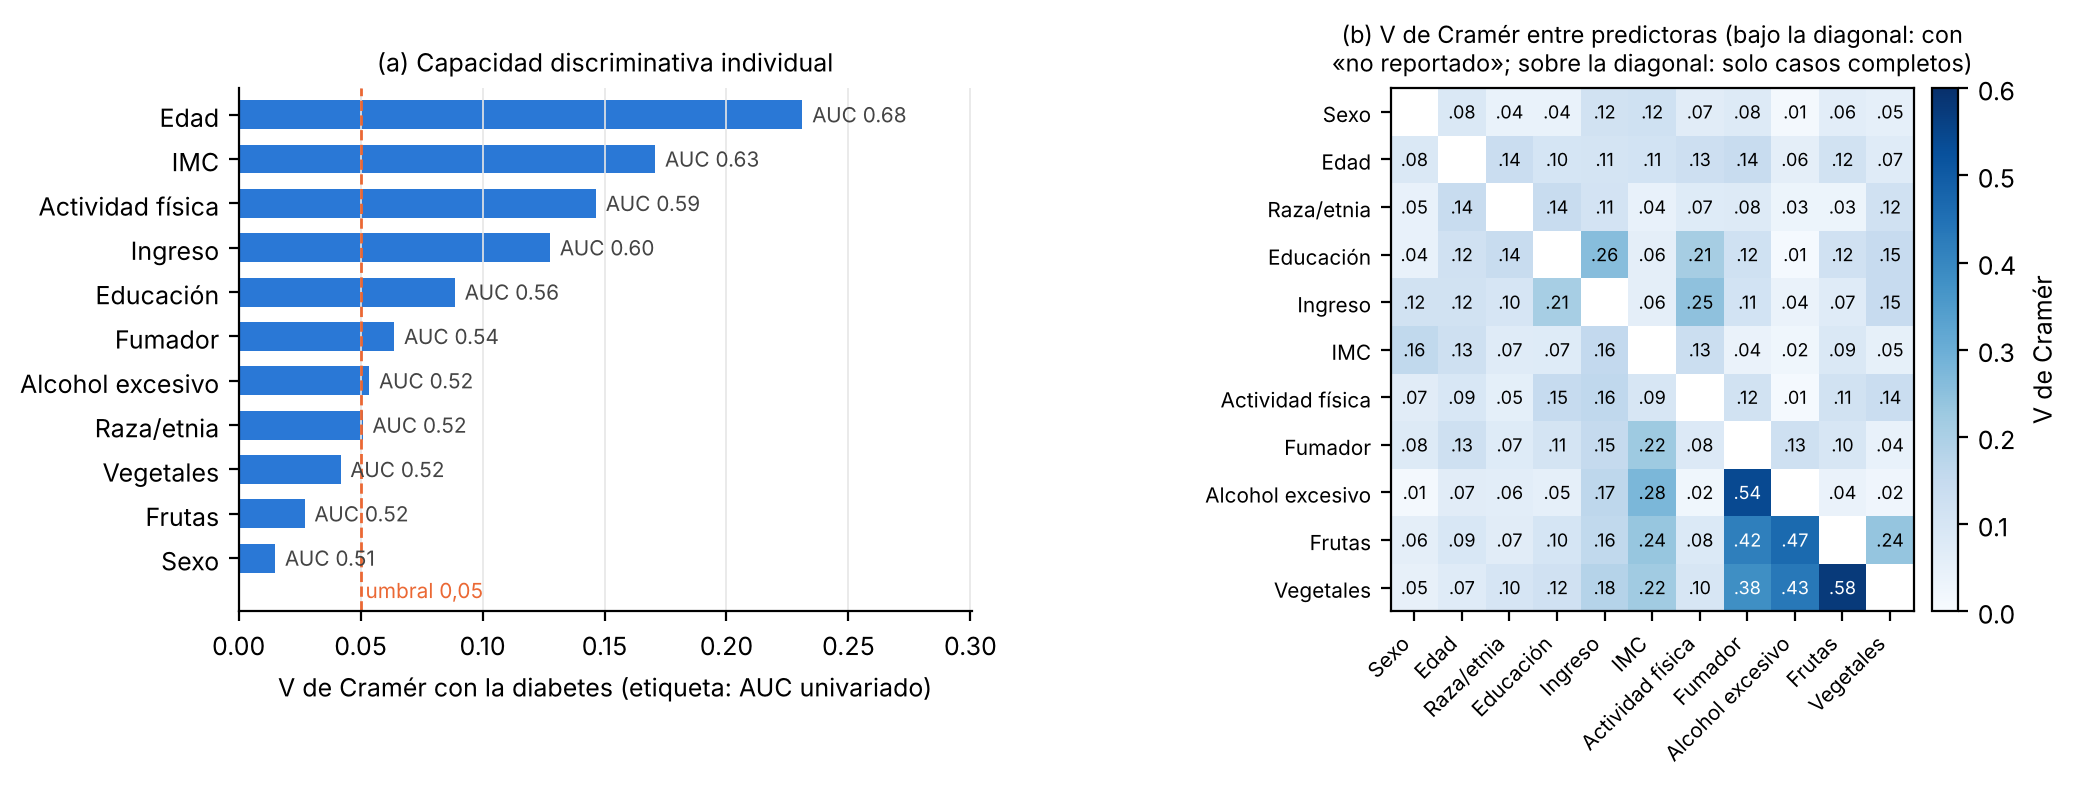

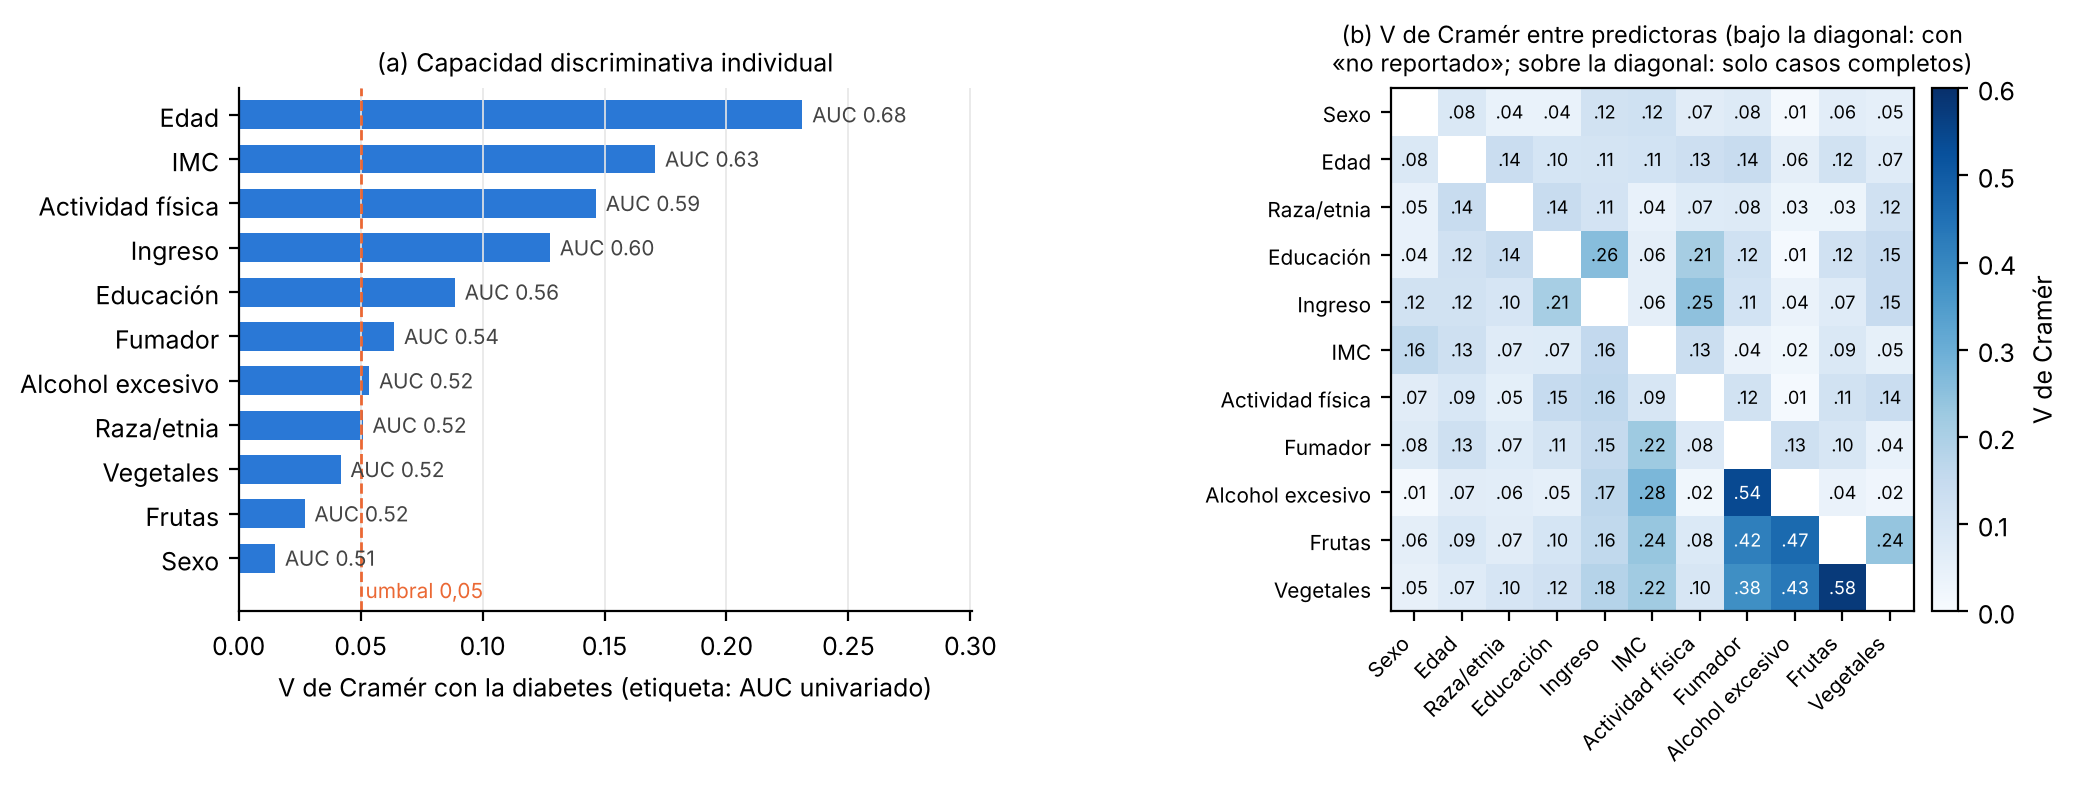

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.0), gridspec_kw={"width_ratios": [1, 1.25]})
t = tabla_ind.iloc[::-1]
ax1.barh(t["Variable"], t["V de Cramér"], color=COLORES[0], height=0.65)
for yy, (v, a) in enumerate(zip(t["V de Cramér"], t["AUC univariado"])):
    ax1.text(v + 0.004, yy, f"AUC {a:.2f}", va="center", fontsize=7.5, color="#444444")
ax1.axvline(0.05, color=COLORES[1], linestyle="--", linewidth=1)
ax1.text(0.052, -0.9, "umbral 0,05", color=COLORES[1], fontsize=7.5)
ax1.set_xlim(0, t["V de Cramér"].max() * 1.3)
ax1.set_ylim(-1.2, len(t) - 0.4)
ax1.set_xlabel("V de Cramér con la diabetes (etiqueta: AUC univariado)")
ax1.set_title("(a) Capacidad discriminativa individual", fontsize=9)
ax1.grid(axis="y", visible=False)
orden = [NOMBRES[c] for c in PREDICTORAS]
# triángulo inferior: con «no reportado»; triángulo superior: solo casos completos
M = np.where(np.tril(np.ones(R.shape, dtype=bool), -1), R.loc[orden, orden].to_numpy(), R_cc.loc[orden, orden].to_numpy())
np.fill_diagonal(M, np.nan)
im = ax2.imshow(M, cmap="Blues", vmin=0, vmax=0.6)
ax2.set_xticks(range(len(orden))); ax2.set_xticklabels(orden, rotation=45, ha="right", fontsize=7.5)
ax2.set_yticks(range(len(orden))); ax2.set_yticklabels(orden, fontsize=7.5)
for i in range(len(orden)):
    for j in range(len(orden)):
        if i != j:
            ax2.text(j, i, f"{M[i, j]:.2f}".lstrip("0"), ha="center", va="center", fontsize=6.5,
                     color="white" if M[i, j] > 0.35 else "black")
ax2.grid(False)
ax2.spines[["top", "right"]].set_visible(True)
ax2.set_title("(b) V de Cramér entre predictoras (bajo la diagonal: con\n«no reportado»; sobre la diagonal: solo casos completos)", fontsize=8.5)
fig.colorbar(im, ax=ax2, fraction=0.04, pad=0.02, label="V de Cramér")
fig.tight_layout()
fig.savefig("figuras/analisis_individual.pdf", bbox_inches="tight")
fig.savefig("figuras/analisis_individual.png", dpi=200, bbox_inches="tight")
fig

### Variables candidatas a eliminar y verificación con los modelos

Criterio: una variable es candidata si su V de Cramér con la diabetes es menor que 0,05 **y** su AUC univariado es menor que 0,55 (prácticamente sin poder discriminativo por sí sola), o si es muy redundante con otra (V entre predictoras > 0,5). Luego se reentrenan los dos modelos sin las candidatas y se compara el AUC de validación con la línea base (prueba *t* pareada sobre los mismos pliegues).

In [9]:
candidatas = tabla_ind.loc[(tabla_ind["V de Cramér"] < 0.05) & (tabla_ind["AUC univariado"] < 0.55), "Variable"].tolist()
redundantes = [(a, b) for (a, b), v in pares.items() if v > 0.5]
inv = {v: k for k, v in NOMBRES.items()}
print("Candidatas por baja discriminación:", candidatas)
print("Pares redundantes (V > 0,5):", redundantes)

escenarios = {"Todas (11)": PREDICTORAS}
acum = []
for nom in tabla_ind["Variable"].iloc[::-1]:          # de menor a mayor V
    if nom in candidatas:
        acum.append(inv[nom])
        escenarios[f"Sin {', '.join(NOMBRES[c] for c in acum)}"] = [c for c in PREDICTORAS if c not in acum]

filas, cv_sel = [], {}
for n in MEJORES:
    for esc, vars_ in escenarios.items():
        res = base_cv[n] if esc.startswith("Todas") else evaluar_cv(pipeline(n, vars_), vars_)
        cv_sel[(n, esc)] = res
        p = np.nan if esc.startswith("Todas") else stats.ttest_rel(res["val_auc"], base_cv[n]["val_auc"])[1]
        filas.append({"Modelo": n, "Variables": esc, "n variables": len(vars_), "Columnas": dimension(n, vars_),
                      "AUC val.": fmt(res["val_auc"]), "Sensibilidad val.": fmt(res["val_sens"]),
                      "Dif. AUC": round((res["val_auc"] - base_cv[n]["val_auc"]).mean(), 4), "valor p": p})
tabla_sel = pd.DataFrame(filas)
tabla_sel.to_csv("resultados/seleccion_variables.csv", index=False)
tabla_sel

Candidatas por baja discriminación: ['Vegetales', 'Frutas', 'Sexo']
Pares redundantes (V > 0,5): [('Frutas', 'Vegetales'), ('Fumador', 'Alcohol excesivo')]


,Modelo,Variables,n variables,Columnas,AUC val.,Sensibilidad val.,Dif. AUC,valor p
0,Regresión logística,Todas (11),11,57,0.76 ± 0.01,0.75 ± 0.01,0.0000,NaN
1,Regresión logística,Sin Sexo,10,55,0.76 ± 0.01,0.75 ± 0.01,-0.0016,0.135310
2,Regresión logística,"Sin Sexo, Frutas",9,52,0.76 ± 0.01,0.75 ± 0.01,-0.0013,0.241491
3,Regresión logística,"Sin Sexo, Frutas, Vegetales",8,49,0.76 ± 0.01,0.75 ± 0.02,-0.0012,0.276973
4,SVM (RBF),Todas (11),11,39,0.76 ± 0.01,0.78 ± 0.01,0.0000,NaN
5,SVM (RBF),Sin Sexo,10,37,0.75 ± 0.01,0.77 ± 0.02,-0.0025,0.040283
6,SVM (RBF),"Sin Sexo, Frutas",9,33,0.75 ± 0.01,0.78 ± 0.02,-0.0021,0.095444
7,SVM (RBF),"Sin Sexo, Frutas, Vegetales",8,29,0.75 ± 0.01,0.78 ± 0.01,-0.0020,0.092639


## 2. Extracción lineal de características: PCA

PCA se agrega al *pipeline* justo después de la codificación, así que en cada pliegue los componentes se calculan solo con los datos de entrenamiento del pliegue. Se recorre el número de componentes *k* y se registra el AUC de validación.

**Criterio para elegir *k*:** el menor número de componentes cuya AUC media de validación no sea significativamente menor que la del modelo sin reducción (prueba *t* pareada, p ≥ 0,05) y cuya pérdida media no supere 0,005. Se escogió este criterio, y no un umbral fijo de varianza explicada, porque con variables *one-hot* gran parte de la varianza está en categorías poco relacionadas con la diabetes; lo que interesa es conservar la capacidad de detección. Como referencia, también se reporta cuántos componentes harían falta para explicar el 90 % de la varianza.

In [10]:
K_PCA = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20, 25, 30, 35, 40, 45, 50]
var_exp, curvas_pca, cv_pca = {}, {}, {}
for n in MEJORES:
    d = dimension(n)
    Z = Pipeline(MEJORES[n]["prep"](PREDICTORAS)).fit(X_ent).transform(X_ent)
    razon = PCA().fit(Z).explained_variance_ratio_
    var_exp[n] = np.cumsum(razon)
    rango = int((razon > 1e-8).sum())   # las columnas one-hot de una misma variable suman 1: el rango es menor que d
    filas = []
    t0 = time.time()
    for k in [k for k in K_PCA if k <= rango]:
        res = evaluar_cv(pipeline(n, reductor=PCA(n_components=k, random_state=SEMILLA)))
        cv_pca[(n, k)] = res
        p = stats.ttest_rel(res["val_auc"], base_cv[n]["val_auc"])[1]
        filas.append({"k": k, "var_exp": var_exp[n][k - 1],
                      "auc_ent": res["ent_auc"].mean(), "auc_val": res["val_auc"].mean(), "ic_val": ic95(res["val_auc"]),
                      "sens_val": res["val_sens"].mean(),
                      "dif": (res["val_auc"] - base_cv[n]["val_auc"]).mean(), "p": p})
    curvas_pca[n] = pd.DataFrame(filas)
    curvas_pca[n].to_csv(f"resultados/pca_curva_{'logistica' if n.startswith('Reg') else 'svm'}.csv", index=False)
    print(f"{n}: {d} columnas, rango {rango}, {time.time()-t0:.0f} s; k para 90 % de varianza = {int(np.argmax(var_exp[n] >= 0.90)) + 1}")
    print(curvas_pca[n].round(4).to_string(index=False))


def elegir_k(curva):
    ok = curva[(curva["p"] >= 0.05) & (curva["dif"] > -0.005)]
    return int(ok["k"].min()) if len(ok) else int(curva["k"].max())


K_ELEGIDO_PCA = {n: elegir_k(curvas_pca[n]) for n in MEJORES}
print("k elegido con PCA:", K_ELEGIDO_PCA)

Regresión logística: 57 columnas, rango 46, 5 s; k para 90 % de varianza = 29
 k  var_exp  auc_ent  auc_val  ic_val  sens_val     dif      p
 1   0.0983   0.5904   0.5903  0.0050    0.5525 -0.1676 0.0000
 2   0.1814   0.5902   0.5897  0.0045    0.5492 -0.1682 0.0000
 3   0.2525   0.6245   0.6230  0.0038    0.5678 -0.1349 0.0000
 4   0.3163   0.6350   0.6337  0.0104    0.5876 -0.1242 0.0001
 5   0.3713   0.6494   0.6478  0.0157    0.5998 -0.1101 0.0001
 6   0.4185   0.6601   0.6585  0.0164    0.5433 -0.0994 0.0002
 8   0.5091   0.6718   0.6705  0.0139    0.5899 -0.0874 0.0001
10   0.5864   0.6733   0.6710  0.0139    0.6021 -0.0869 0.0000
15   0.7223   0.6836   0.6808  0.0152    0.6229 -0.0772 0.0001
20   0.7979   0.6914   0.6866  0.0142    0.6193 -0.0713 0.0001
25   0.8626   0.6964   0.6912  0.0153    0.6295 -0.0667 0.0001
30   0.9126   0.7230   0.7166  0.0078    0.6606 -0.0413 0.0002
35   0.9555   0.7576   0.7519  0.0112    0.7290 -0.0060 0.0010
40   0.9859   0.7616   0.7560  0.0112   

SVM (RBF): 39 columnas, rango 26, 745 s; k para 90 % de varianza = 13
 k  var_exp  auc_ent  auc_val  ic_val  sens_val     dif      p
 1   0.1436   0.5230   0.5212  0.0284    0.7621 -0.2345 0.0001
 2   0.2697   0.6232   0.6227  0.0093    0.6570 -0.1330 0.0000
 3   0.3674   0.7131   0.7114  0.0108    0.7994 -0.0443 0.0000
 4   0.4569   0.7420   0.7399  0.0130    0.7766 -0.0159 0.0000
 5   0.5430   0.7446   0.7419  0.0111    0.7677 -0.0138 0.0001
 6   0.6155   0.7456   0.7433  0.0111    0.7730 -0.0124 0.0003
 8   0.7345   0.7479   0.7444  0.0110    0.7783 -0.0113 0.0005
10   0.8223   0.7500   0.7449  0.0108    0.7736 -0.0109 0.0007
15   0.9477   0.7617   0.7533  0.0136    0.7723 -0.0025 0.0048
20   0.9834   0.7649   0.7556  0.0129    0.7763 -0.0002 0.3498
25   0.9995   0.7658   0.7557  0.0130    0.7759 -0.0001 0.3662
k elegido con PCA: {'Regresión logística': 45, 'SVM (RBF)': 20}


## 3. Extracción no lineal de características: UMAP

UMAP construye un grafo de vecinos en el espacio codificado y busca una representación de baja dimensión que lo preserve. Es mucho más costoso que PCA, por eso:

- La búsqueda se hace con los mismos 5 pliegues de la submuestra de 20.000 registros. En cada pliegue UMAP se ajusta solo con la parte de entrenamiento y se aplica (`transform`) a la de validación; el *embedding* de cada pliegue y cada *k* se calcula una vez y se reutiliza para los dos valores de hiperparámetro del clasificador. Los pliegues se reparten entre los 2 núcleos con `joblib`; cada UMAP usa su propia semilla fija, así que el resultado es reproducible.
- Después de UMAP las coordenadas se estandarizan, porque su escala no tiene relación con la del espacio original y la SVM RBF depende de distancias.
- Hiperparámetros de UMAP: `n_neighbors = 30` (algo más que el valor por defecto, para conservar más estructura global en datos con muchos perfiles repetidos), `min_dist = 0.0` (recomendado cuando el *embedding* se usa para clasificar y no para visualizar) y métrica euclidiana sobre la codificación de cada modelo.
- Como la geometría del espacio cambia, se reajusta un hiperparámetro de cada clasificador: C ∈ {0,01; 1} en la regresión logística y gamma ∈ {0,1; «scale»} en la SVM.
- Se evalúan dos variantes. **UMAP no supervisado** (la versión estándar, que no ve la etiqueta) y **UMAP supervisado**, que al construir el *embedding* también usa la etiqueta de los registros de entrenamiento (`target_weight = 0.5`). La variante supervisada sigue sin fuga de información: la etiqueta solo se usa en la parte de entrenamiento de cada pliegue, y los registros de validación y prueba se proyectan con `transform`, sin etiqueta.

Ojo: un `Pipeline` de scikit-learn le pasa `y` a todos sus pasos al ajustar, y `umap.UMAP.fit(X, y)` se vuelve supervisado si recibe `y`. Para la variante no supervisada se usa la clase `UMAPNoSupervisado`, que descarta `y`.

El criterio para elegir *k* es el mismo que en PCA, comparado contra la misma línea base; si ningún *k* lo cumple, se toma el de mayor AUC de validación.

In [11]:
from joblib import Parallel, delayed


class UMAPNoSupervisado(umap.UMAP):
    # UMAP estándar: ignora la etiqueta aunque el Pipeline se la pase
    def fit(self, X, y=None, *args, **kwargs):
        return super().fit(X, None, *args, **kwargs)

    def fit_transform(self, X, y=None, *args, **kwargs):
        return super().fit_transform(X, None, *args, **kwargs)


K_UMAP = [2, 3, 5, 8, 10]
PARAM_UMAP = dict(n_neighbors=30, min_dist=0.0, metric="euclidean", random_state=SEMILLA)
VARIANTES_UMAP = {"UMAP": lambda k: UMAPNoSupervisado(n_components=k, **PARAM_UMAP),
                  "UMAP supervisado": lambda k: umap.UMAP(n_components=k, target_weight=0.5, **PARAM_UMAP)}
CLASIF_UMAP = {
    "Regresión logística": {"C=0.01": lambda: LogisticRegression(C=0.01, class_weight="balanced", max_iter=2000),
                            "C=1": lambda: LogisticRegression(C=1, class_weight="balanced", max_iter=2000)},
    "SVM (RBF)": {"gamma=0.1": lambda: SVC(kernel="rbf", C=1, gamma=0.1, class_weight="balanced"),
                  "gamma=scale": lambda: SVC(kernel="rbf", C=1, gamma="scale", class_weight="balanced")},
}
PLIEGUES = list(cv.split(X_bus, y_bus))


def puntuar(modelo, Z, yv):
    s = modelo.decision_function(Z)
    pr = modelo.predict(Z)
    return {"auc": roc_auc_score(yv, s), "sens": recall_score(yv, pr), "espec": recall_score(yv, pr, pos_label=0),
            "prec": precision_score(yv, pr, zero_division=0), "f1": f1_score(yv, pr)}


def tarea_umap(n, var, k, f):
    # Un pliegue: ajusta codificación + UMAP con la parte de entrenamiento y evalúa los clasificadores
    warnings.filterwarnings("ignore")
    i_a, i_b = PLIEGUES[f]
    Xa, Xb, ya, yb = X_bus.iloc[i_a], X_bus.iloc[i_b], y_bus.iloc[i_a], y_bus.iloc[i_b]
    prep = Pipeline(MEJORES[n]["prep"](PREDICTORAS) + [("umap", VARIANTES_UMAP[var](k)), ("escalar2", StandardScaler())])
    Za = prep.fit_transform(Xa, ya)          # la variante no supervisada descarta ya
    Zb = prep.transform(Xb)                  # validación: sin etiqueta
    salida = {}
    for h, crear in CLASIF_UMAP[n].items():
        m = crear().fit(Za, ya)
        salida[h] = {"ent": puntuar(m, Za, ya), "val": puntuar(m, Zb, yb)}
    return (n, var, k, f), salida


t0 = time.time()
tareas = [(n, var, k, f) for n in MEJORES for var in VARIANTES_UMAP for k in K_UMAP for f in range(N_FOLDS)]
salidas = dict(Parallel(n_jobs=N_JOBS, verbose=0)(delayed(tarea_umap)(*t) for t in tareas))
print(f"{len(tareas)} ajustes de UMAP en {time.time() - t0:.0f} s")

cv_umap = {}           # (modelo, variante, k, hiperparámetro) -> métricas por pliegue
for n in MEJORES:
    for var in VARIANTES_UMAP:
        for k in K_UMAP:
            for h in CLASIF_UMAP[n]:
                cv_umap[(n, var, k, h)] = {f"{p}_{m}": np.array([salidas[(n, var, k, f)][h][p][m] for f in range(N_FOLDS)])
                                           for p in ["ent", "val"] for m in METRICAS}
            print(f"{n:20s} {var:17s} k={k:2d} " + "  ".join(
                f"{h}: AUC {fmt(cv_umap[(n, var, k, h)]['val_auc'])}" for h in CLASIF_UMAP[n]))

/usr/local/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


100 ajustes de UMAP en 1767 s
Regresión logística  UMAP              k= 2 C=0.01: AUC 0.53 ± 0.02  C=1: AUC 0.53 ± 0.02
Regresión logística  UMAP              k= 3 C=0.01: AUC 0.54 ± 0.03  C=1: AUC 0.55 ± 0.03
Regresión logística  UMAP              k= 5 C=0.01: AUC 0.59 ± 0.04  C=1: AUC 0.59 ± 0.03
Regresión logística  UMAP              k= 8 C=0.01: AUC 0.60 ± 0.03  C=1: AUC 0.61 ± 0.04
Regresión logística  UMAP              k=10 C=0.01: AUC 0.61 ± 0.03  C=1: AUC 0.63 ± 0.03
Regresión logística  UMAP supervisado  k= 2 C=0.01: AUC 0.54 ± 0.03  C=1: AUC 0.54 ± 0.02
Regresión logística  UMAP supervisado  k= 3 C=0.01: AUC 0.56 ± 0.02  C=1: AUC 0.56 ± 0.04
Regresión logística  UMAP supervisado  k= 5 C=0.01: AUC 0.57 ± 0.04  C=1: AUC 0.57 ± 0.02
Regresión logística  UMAP supervisado  k= 8 C=0.01: AUC 0.57 ± 0.02  C=1: AUC 0.56 ± 0.04
Regresión logística  UMAP supervisado  k=10 C=0.01: AUC 0.56 ± 0.02  C=1: AUC 0.56 ± 0.03
SVM (RBF)            UMAP              k= 2 gamma=0.1: AUC 0.58 ± 0.02

In [12]:
curvas_umap, K_ELEGIDO_UMAP, H_UMAP = {}, {}, {}


def elegir_k_umap(curva):
    ok = curva[(curva["p"] >= 0.05) & (curva["dif"] > -0.005)]
    return int(ok["k"].min()) if len(ok) else int(curva.loc[curva["auc_val"].idxmax(), "k"])


for n in MEJORES:
    for var in VARIANTES_UMAP:
        filas = []
        for k in K_UMAP:
            h = max(CLASIF_UMAP[n], key=lambda h: cv_umap[(n, var, k, h)]["val_auc"].mean())
            res = cv_umap[(n, var, k, h)]
            filas.append({"k": k, "hiperparámetro": h, "auc_ent": res["ent_auc"].mean(), "auc_val": res["val_auc"].mean(),
                          "ic_val": ic95(res["val_auc"]), "sens_val": res["val_sens"].mean(),
                          "dif": (res["val_auc"] - base_cv[n]["val_auc"]).mean(),
                          "p": stats.ttest_rel(res["val_auc"], base_cv[n]["val_auc"])[1]})
        c = pd.DataFrame(filas)
        curvas_umap[(n, var)] = c
        K_ELEGIDO_UMAP[(n, var)] = elegir_k_umap(c)
        H_UMAP[(n, var)] = c.set_index("k").loc[K_ELEGIDO_UMAP[(n, var)], "hiperparámetro"]
        sufijo = ("logistica" if n.startswith("Reg") else "svm") + ("_supervisado" if "super" in var else "")
        c.to_csv(f"resultados/umap_curva_{sufijo}.csv", index=False)
        print(n, "|", var); print(c.round(4).to_string(index=False))
print("k elegido con UMAP:", K_ELEGIDO_UMAP, H_UMAP)

Regresión logística | UMAP
 k hiperparámetro  auc_ent  auc_val  ic_val  sens_val     dif      p
 2            C=1   0.5278   0.5257  0.0179    0.5139 -0.2322 0.0000
 3            C=1   0.5458   0.5476  0.0312    0.5129 -0.2103 0.0001
 5            C=1   0.5972   0.5945  0.0326    0.5532 -0.1634 0.0004
 8            C=1   0.6130   0.6105  0.0369    0.6071 -0.1474 0.0007
10            C=1   0.6303   0.6304  0.0254    0.5995 -0.1275 0.0002
Regresión logística | UMAP supervisado
 k hiperparámetro  auc_ent  auc_val  ic_val  sens_val     dif      p
 2         C=0.01   0.9147   0.5397  0.0264    0.1999 -0.2182 0.0000
 3         C=0.01   0.9569   0.5621  0.0228    0.1394 -0.1958 0.0000
 5            C=1   0.9830   0.5733  0.0207    0.1024 -0.1846 0.0000
 8         C=0.01   0.9839   0.5714  0.0191    0.0783 -0.1865 0.0000
10            C=1   0.9867   0.5578  0.0313    0.1153 -0.2001 0.0002
SVM (RBF) | UMAP
 k hiperparámetro  auc_ent  auc_val  ic_val  sens_val     dif      p
 2    gamma=scale   

### Figura: varianza explicada y efecto del número de componentes

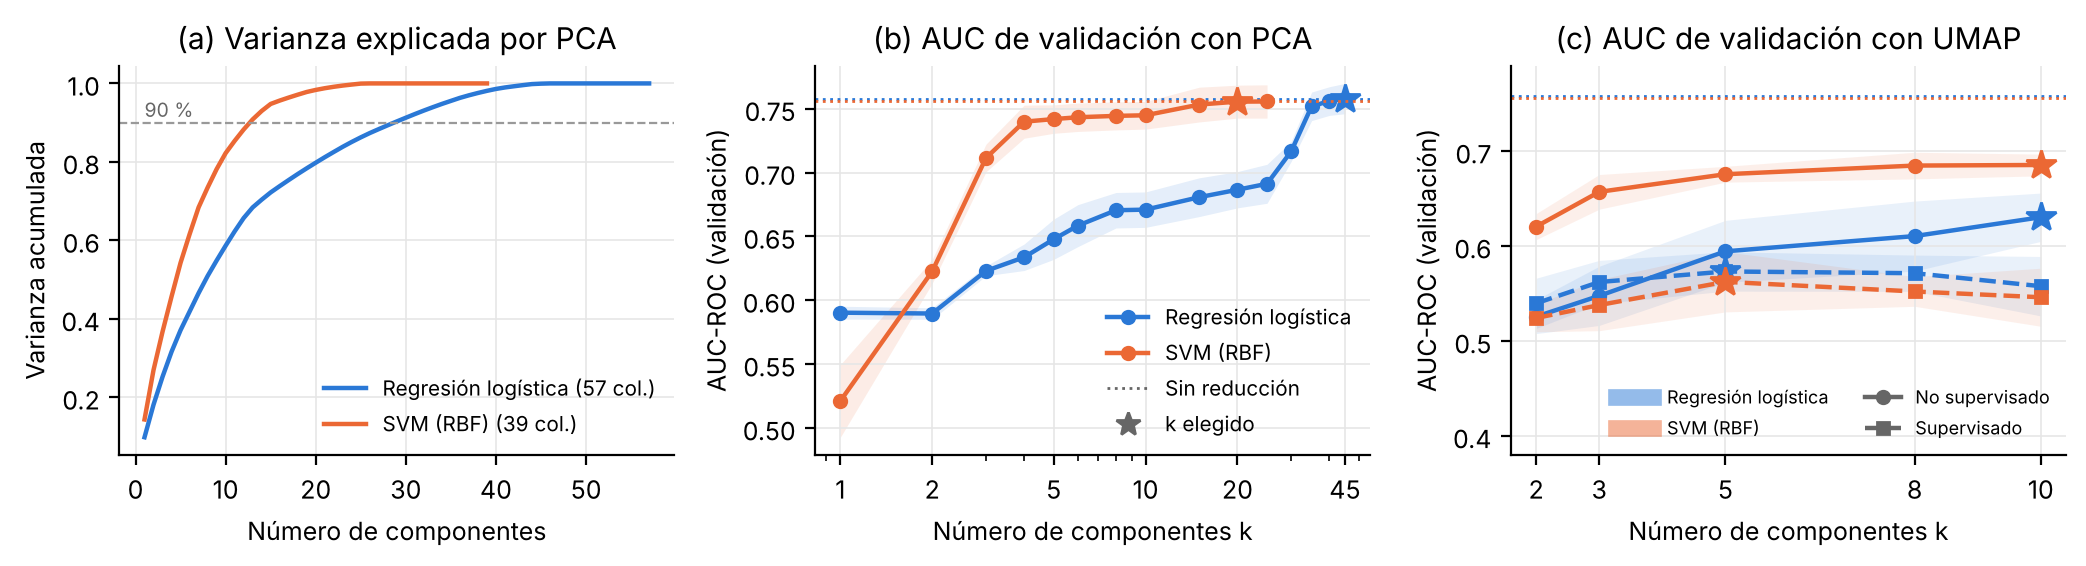

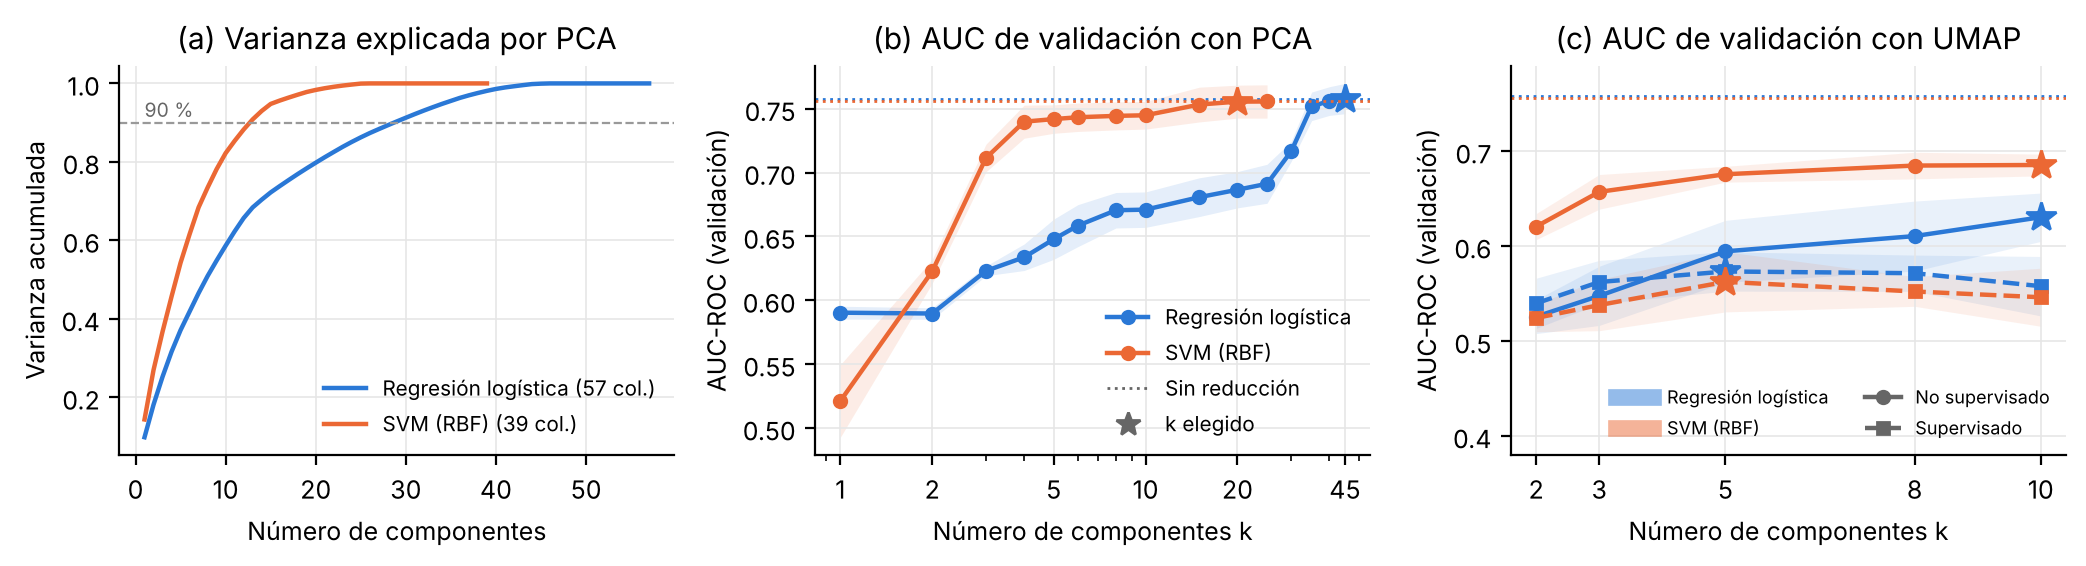

In [13]:
fig, ejes = plt.subplots(1, 3, figsize=(10.5, 2.9))
for i, n in enumerate(MEJORES):
    ejes[0].plot(np.arange(1, len(var_exp[n]) + 1), var_exp[n], color=COLORES[i], label=f"{n} ({len(var_exp[n])} col.)")
ejes[0].axhline(0.90, color="#999999", linestyle="--", linewidth=0.8)
ejes[0].text(1, 0.915, "90 %", fontsize=7, color="#666666")
ejes[0].set(title="(a) Varianza explicada por PCA", xlabel="Número de componentes", ylabel="Varianza acumulada")
ejes[0].legend(loc="lower right")

ax = ejes[1]
for i, n in enumerate(MEJORES):
    c = curvas_pca[n]
    ax.plot(c["k"], c["auc_val"], marker="o", color=COLORES[i], label=n)
    ax.fill_between(c["k"], c["auc_val"] - c["ic_val"], c["auc_val"] + c["ic_val"], color=COLORES[i], alpha=0.12, linewidth=0)
    ax.axhline(base_cv[n]["val_auc"].mean(), color=COLORES[i], linestyle=":", linewidth=1)
    k_e = K_ELEGIDO_PCA[n]
    ax.plot([k_e], [c.set_index("k").loc[k_e, "auc_val"]], marker="*", markersize=11, color=COLORES[i])
ax.plot([], [], color="#666666", linestyle=":", linewidth=1, label="Sin reducción")
ax.plot([], [], color="#666666", marker="*", linestyle="none", markersize=9, label="k elegido")
ax.set(title="(b) AUC de validación con PCA", xlabel="Número de componentes k", ylabel="AUC-ROC (validación)")
ax.set_xscale("log"); ax.set_xticks([1, 2, 5, 10, 20, 45]); ax.set_xticklabels(["1", "2", "5", "10", "20", "45"])
ax.legend(loc="lower right")

ax = ejes[2]
for i, n in enumerate(MEJORES):
    for var, estilo, marca in [("UMAP", "-", "o"), ("UMAP supervisado", "--", "s")]:
        c = curvas_umap[(n, var)]
        ax.plot(c["k"], c["auc_val"], marker=marca, linestyle=estilo, color=COLORES[i])
        ax.fill_between(c["k"], c["auc_val"] - c["ic_val"], c["auc_val"] + c["ic_val"], color=COLORES[i], alpha=0.10, linewidth=0)
        k_e = K_ELEGIDO_UMAP[(n, var)]
        ax.plot([k_e], [c.set_index("k").loc[k_e, "auc_val"]], marker="*", markersize=11, color=COLORES[i])
    ax.axhline(base_cv[n]["val_auc"].mean(), color=COLORES[i], linestyle=":", linewidth=1)
    ax.plot([], [], color=COLORES[i], linewidth=6, alpha=0.5, label=n)
ax.plot([], [], color="#666666", linestyle="-", marker="o", label="No supervisado")
ax.plot([], [], color="#666666", linestyle="--", marker="s", label="Supervisado")
ax.set(title="(c) AUC de validación con UMAP", xlabel="Número de componentes k", ylabel="AUC-ROC (validación)")
ax.set_xticks(K_UMAP)
ax.set_ylim(0.38, 0.79)
ax.legend(loc="lower right", fontsize=6.5, ncol=2)
fig.tight_layout()
fig.savefig("figuras/pca_umap_componentes.pdf", bbox_inches="tight")
fig.savefig("figuras/pca_umap_componentes.png", dpi=200, bbox_inches="tight")
fig

## 4. Evaluación final en el conjunto de prueba

Para cada modelo se comparan: sin reducción, sin las variables candidatas, PCA con el *k* elegido (y con *k* = 10 si el elegido supera las 11 variables originales), UMAP y UMAP supervisado. Se reajustan igual que en la sección 1: la regresión logística con todo el conjunto de entrenamiento y la SVM con la submuestra de 40.000 registros. UMAP también se ajusta con esa submuestra, porque construir su grafo de vecinos con 274 mil registros no es viable con los recursos disponibles; la regresión logística con UMAP se entrena entonces sobre esos mismos 40.000 *embeddings*. Los ajustes se reparten entre los 2 núcleos. El IC del 95 % en prueba se estima con 1.000 remuestreos *bootstrap*.

In [14]:
rng = np.random.default_rng(SEMILLA)
y_np = y_pru.to_numpy()
indices = [rng.integers(0, len(y_np), len(y_np)) for _ in range(1000)]
sel_final = [c for c in PREDICTORAS if NOMBRES[c] not in candidatas]
esc_sel = [e for e in escenarios if not e.startswith("Todas")][-1] if candidatas else None


def version(n, tipo):
    # Devuelve (pipeline, variables, resultados de validación cruzada, dimensión)
    if tipo == "Sin reducción":
        return pipeline(n), PREDICTORAS, base_cv[n], dimension(n)
    if tipo == "Selección de variables":
        return pipeline(n, sel_final), sel_final, cv_sel[(n, esc_sel)], dimension(n, sel_final)
    if tipo.startswith("PCA"):
        k = K_ELEGIDO_PCA[n] if tipo == "PCA" else 10
        return pipeline(n, reductor=PCA(n_components=k, random_state=SEMILLA)), PREDICTORAS, cv_pca[(n, k)], k
    k, h = K_ELEGIDO_UMAP[(n, tipo)], H_UMAP[(n, tipo)]
    return (pipeline(n, reductor=VARIANTES_UMAP[tipo](k), escalar_despues=True, modelo=CLASIF_UMAP[n][h]()),
            PREDICTORAS, cv_umap[(n, tipo, k, h)], k)


def ajustar_y_probar(n, tipo):
    warnings.filterwarnings("ignore")
    pipe, vars_, _, _ = version(n, tipo)
    usa_sub = n.startswith("SVM") or tipo.startswith("UMAP")
    Xf, yf = (X_sub, y_sub) if usa_sub else (X_ent, y_ent)
    t0 = time.time()
    pipe.fit(Xf[vars_], yf)
    s = pipe.decision_function(X_pru[vars_])
    pr = pipe.predict(X_pru[vars_])
    return (n, tipo), (s, pr, len(yf), time.time() - t0)


TIPOS = {n: (["Sin reducción"] + (["Selección de variables"] if candidatas else []) + ["PCA"]
             + (["PCA (k = 10)"] if K_ELEGIDO_PCA[n] > 10 else []) + list(VARIANTES_UMAP)) for n in MEJORES}
trabajos = [(n, t) for n in MEJORES for t in TIPOS[n]]
# primero los más lentos (UMAP), para repartir mejor la carga entre los núcleos
trabajos.sort(key=lambda t: (not t[1].startswith("UMAP"), not t[0].startswith("SVM")))
t0 = time.time()
predicciones = dict(Parallel(n_jobs=N_JOBS)(delayed(ajustar_y_probar)(*t) for t in trabajos))
print(f"{len(trabajos)} modelos finales en {time.time() - t0:.0f} s")

filas = []
for n in MEJORES:
    d0 = dimension(n)
    for tipo in TIPOS[n]:
        _, _, res, dim = version(n, tipo)
        s, pr, n_ajuste, dur = predicciones[(n, tipo)]
        auc_b = np.percentile([roc_auc_score(y_np[i], s[i]) for i in indices], [2.5, 97.5])
        sens_b = np.percentile([recall_score(y_np[i], pr[i]) for i in indices], [2.5, 97.5])
        filas.append({"Modelo": n, "Versión": tipo, "Dimensión": dim, "Reducción (%)": round(100 * (1 - dim / d0), 1),
                      "Var. explicada PCA": round(var_exp[n][dim - 1], 2) if tipo.startswith("PCA") else np.nan,
                      "AUC ent.": fmt(res["ent_auc"]), "AUC val.": fmt(res["val_auc"]), "Sens. val.": fmt(res["val_sens"]),
                      "AUC prueba": f"{roc_auc_score(y_np, s):.2f} [{auc_b[0]:.2f}, {auc_b[1]:.2f}]",
                      "Sens. prueba": f"{recall_score(y_np, pr):.2f} [{sens_b[0]:.2f}, {sens_b[1]:.2f}]",
                      "Espec. prueba": round(recall_score(y_np, pr, pos_label=0), 2),
                      "Prec. prueba": round(precision_score(y_np, pr), 2), "F1 prueba": round(f1_score(y_np, pr), 2),
                      "Registros de ajuste": n_ajuste, "Tiempo ajuste + prueba (s)": round(dur, 1)})
tabla_red = pd.DataFrame(filas)
tabla_red.to_csv("resultados/reduccion_dimension_final.csv", index=False)
tabla_red.T

/usr/local/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


12 modelos finales en 844 s


,0,1,2,3,4,5,6,7,8,9,10,11
Modelo,Regresión logística,Regresión logística,Regresión logística,Regresión logística,Regresión logística,Regresión logística,SVM (RBF),SVM (RBF),SVM (RBF),SVM (RBF),SVM (RBF),SVM (RBF)
Versión,Sin reducción,Selección de variables,PCA,PCA (k = 10),UMAP,UMAP supervisado,Sin reducción,Selección de variables,PCA,PCA (k = 10),UMAP,UMAP supervisado
Dimensión,57,49,45,10,10,5,39,29,20,10,10,5
Reducción (%),0.0,14.0,21.1,82.5,82.5,91.2,0.0,25.6,48.7,74.4,74.4,87.2
Var. explicada PCA,NaN,NaN,1.0,0.59,NaN,NaN,NaN,NaN,0.98,0.82,NaN,NaN
AUC ent.,0.76 ± 0.00,0.76 ± 0.00,0.76 ± 0.00,0.67 ± 0.00,0.63 ± 0.01,0.98 ± 0.00,0.77 ± 0.00,0.76 ± 0.00,0.76 ± 0.00,0.75 ± 0.00,0.70 ± 0.00,0.98 ± 0.00
AUC val.,0.76 ± 0.01,0.76 ± 0.01,0.76 ± 0.01,0.67 ± 0.01,0.63 ± 0.03,0.57 ± 0.02,0.76 ± 0.01,0.75 ± 0.01,0.76 ± 0.01,0.74 ± 0.01,0.69 ± 0.01,0.56 ± 0.03
Sens. val.,0.75 ± 0.01,0.75 ± 0.02,0.75 ± 0.01,0.60 ± 0.02,0.60 ± 0.03,0.10 ± 0.02,0.78 ± 0.01,0.78 ± 0.01,0.78 ± 0.01,0.77 ± 0.01,0.71 ± 0.04,0.08 ± 0.01
AUC prueba,"0.77 [0.76, 0.77]","0.77 [0.76, 0.77]","0.77 [0.76, 0.77]","0.68 [0.68, 0.69]","0.60 [0.60, 0.61]","0.62 [0.61, 0.62]","0.77 [0.76, 0.77]","0.76 [0.76, 0.77]","0.77 [0.76, 0.77]","0.76 [0.75, 0.76]","0.69 [0.69, 0.70]","0.55 [0.55, 0.56]"
Sens. prueba,"0.75 [0.74, 0.76]","0.74 [0.74, 0.75]","0.75 [0.74, 0.76]","0.62 [0.61, 0.63]","0.56 [0.55, 0.57]","0.18 [0.17, 0.18]","0.80 [0.80, 0.81]","0.80 [0.79, 0.81]","0.80 [0.80, 0.81]","0.81 [0.80, 0.82]","0.70 [0.69, 0.71]","0.14 [0.13, 0.14]"


## 5. Resumen

La tabla anterior es la que se resume en el reporte (Tabla de reducción de dimensión). Los valores de entrenamiento y validación son media ± IC del 95 % sobre los 5 pliegues; los de prueba incluyen el IC *bootstrap*.